Goals 

- Create a UMAP that is informed by the spatial location of L3 cell types (control cells only)
- Project non-control cells into that UMAP
- Write out final objects

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import os 

import numpy as np
import pandas as pd
import rapids_singlecell as rsc
import scanpy as sc
from dotenv import dotenv_values

from hm3d_utils.manifold import project_to_ref_umap
from hm3d_utils.utils import write_clean_h5ad
from project_utils import FileTracker

In [3]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

CENTROID_FP = DATADIR / "7_spatial" / "analyses" / "L3_umap_cluster_centroids.csv"

OUTDIR = DATADIR / "9_objects" / "singlecell"
ADATA_FP = OUTDIR / "hypomap3d_singlecell_all.h5ad"

tracker = FileTracker(log_file=DATADIR/'tracked_files.toml')


TAXONOMIC_KEYS = ['L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID']

CENTER = ('6.72')
SF = 30

### Load single cell object

In [4]:
adata = sc.read_h5ad(ADATA_FP, backed="r")
adata_c = adata[adata.obs['IsControl']].to_memory()
adata_nc = adata[~adata.obs['IsControl']].to_memory()

In [ ]:
adata_c.obsm["X_umap_raw"] = adata_c.obsm["X_umap"].copy()
adata_nc.obsm["X_umap_raw"] = adata_nc.obsm["X_umap"].copy()

In [6]:
adata_c

AnnData object with n_obs × n_vars = 896959 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    obsm: 'X_embed', 'X_umap', 'X_umap_raw'

In [7]:
adata_nc

AnnData object with n_obs × n_vars = 667105 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    obsm: 'X_embed', 'X_umap', 'X_umap_raw'

### Compute nearest neighbors as normal

In [ ]:
rsc.pp.neighbors(adata_c, n_neighbors=15, use_rep='X_embed')

### Adjust connectivity by taxonomic agreement

In [9]:
# For each edge in the graph, weight by the number of labels that match across all 5 levels
# If matches only up to level 2 then is would be (2/5) * connectivity
# Thereby, weakening edges connecting 'unrelated' cell-types
# Connections will never be truly broken, instead connectivites are clipped to a minimum of 0.05

taxonomy_labels = np.column_stack(
    [
        adata_c.obs[key].cat.codes
        for key in TAXONOMIC_KEYS
    ]
)

C = adata_c.obsp['connectivities'].copy()

for i in range(C.indptr.size - 1):
    start = C.indptr[i]
    end = C.indptr[i+1]
    
    ptr_label = taxonomy_labels[i]
    
    indices = C.indices[start:end]
    indices_labels = taxonomy_labels[indices]

    match = (indices_labels == ptr_label)

    C.data[start:end] *= np.mean(match, axis=1)

C.data = np.clip(C.data, 0.05, 1)

# We write back the modified connectivity matrix
adata_c.obsp['connectivities'] = C

### Setup initial coordinates

In [ ]:
centroid_df = pd.read_csv(CENTROID_FP, index_col=0)
centroid_df['cluster_name'] = centroid_df['cluster_name'].str.split().str[0]

L3_categories = adata_c.obs['L3_ID'].cat.categories.to_numpy()

In [ ]:
centroid_df = centroid_df.set_index("cluster_name").loc[L3_categories]
L3_centroids = centroid_df[['x', 'y']].values

X = L3_centroids[adata_c.obs['L3_ID'].cat.codes]

In [ ]:
# We need to rescale coordinates to match UMAP intentions
max_ = np.max(X, axis=0)
min_ = np.min(X, axis=0)

center = (max_ + min_) / 2
half_range = (max_ - min_) / 2

X = (X - center) * (SF/half_range)

# Flip vertical axis
X[:, 1] *= -1

X

array([[ -0.03215434, -18.37253057],
       [  2.18649518, -19.93414864],
       [  1.39871383, -17.37535278],
       ...,
       [ -2.68488746,  -0.3480715 ],
       [  6.3022508 , -24.97648166],
       [ -2.68488746,  -0.3480715 ]], shape=(896959, 2))

In [ ]:
# Non-neuronal cell-types are moved to upper right with adequate jitter
nn_mask = adata_c.obs['L3_ID'].str.startswith('NN').values
n_nn = np.sum(nn_mask)

rng = np.random.default_rng(0)

X[nn_mask] = np.array([[SF-2, SF-2]]) + rng.random((n_nn,2)) * 2

In [ ]:
adata_c.obsm['X_umap_init'] = X

### Compute UMAP

In [ ]:
adata_c.obs['regions'] = adata_c.obs['L3_descr'].str.split().str[1].astype('category')
adata_c.obs.loc[(adata_c.obs['L3_descr'].str.startswith('NN') & (~adata_c.obs['L3_descr'].isna())), 'regions'] = np.nan
adata_c.obs['regions'] = adata_c.obs['regions'].cat.remove_unused_categories()

len(adata_c.obs['regions'].cat.categories)

42

In [16]:
rsc.tl.umap(
    adata_c,
    min_dist=0.6,
    spread=1,
    init_pos='X_umap_init',
    random_state=67
)

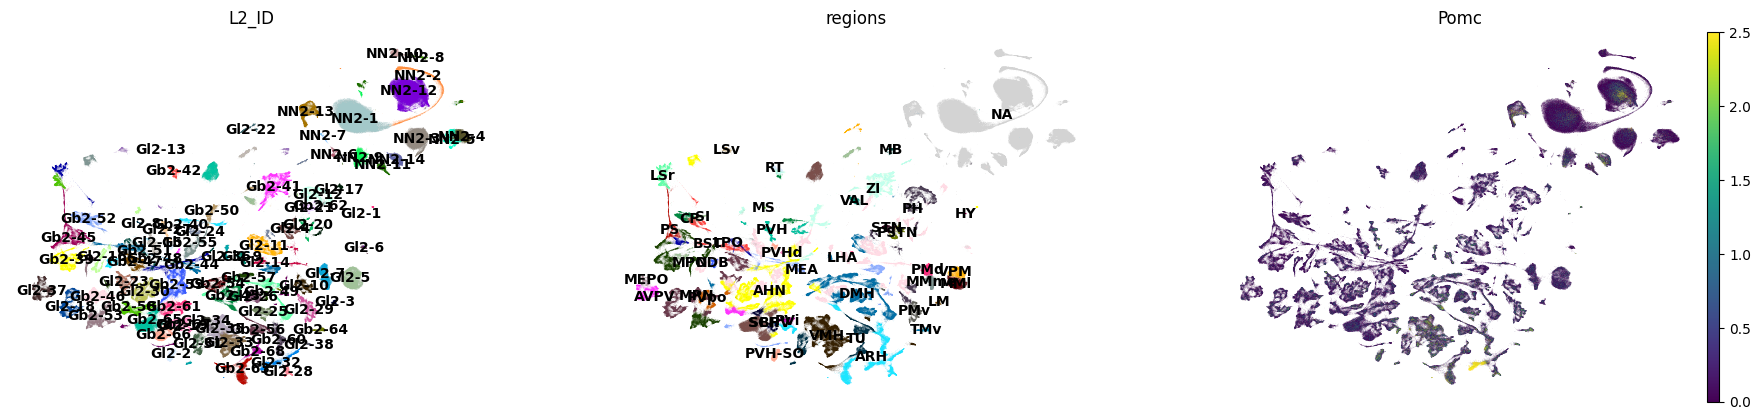

In [17]:
sc.pl.umap(
    adata_c,
    color=['L2_ID', 'regions', 'Pomc'],
    palette=sc.pl.palettes.default_102,
    legend_loc='on data',
    frameon=False,
    vmax=2.5
)

In [18]:
adata_c

AnnData object with n_obs × n_vars = 896959 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like', 'regions'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'neighbors', 'umap', 'L2_ID_colors', 'regions_colors'
    obsm: 'X_embed', 'X_umap', 'X_umap_raw', 'X_umap_init'
    obsp: 'distances', 'connectivities'

### Project NC 

In [19]:
adata_nc.obsm['X_umap'], _ = project_to_ref_umap(
    adata_c.obsm["X_embed"],
    adata_nc.obsm["X_embed"],
    adata_c.obsm["X_umap"],
    spread=1.0,
    min_dist=0.6,
    verbose=True,
    use_gpu=True,
    n_epochs=100,
    seed=0
)

  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs


In [20]:
adata_nc.obs['regions'] = adata_nc.obs['L3_descr'].str.split().str[1].astype('category')
adata_nc.obs.loc[(adata_nc.obs['L3_descr'].str.startswith('NN') & (~adata_nc.obs['L3_descr'].isna())), 'regions'] = np.nan
adata_nc.obs['regions'] = adata_nc.obs['regions'].cat.remove_unused_categories()

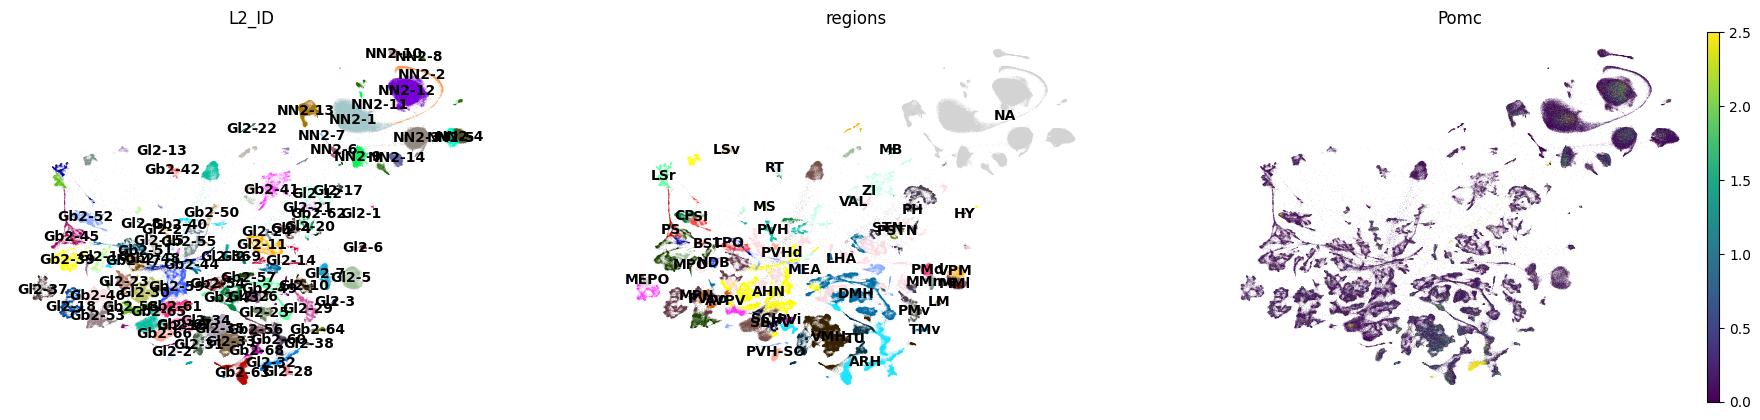

In [21]:
sc.pl.umap(
    adata_nc,
    color=['L2_ID', 'regions', 'Pomc'],
    palette=sc.pl.palettes.default_102,
    legend_loc='on data',
    frameon=False,
    vmax=2.5
)

### Let's write out all objects

In [22]:
adata_full = sc.concat([adata_c, adata_nc], join="inner")

In [23]:
adata_full.var = adata_c.var.loc[adata_full.var.index, :]
adata_full.obs.drop(columns="regions", inplace=True)
adata_full.obsm["X_spatial_umap"] = adata_full.obsm["X_umap"].copy()
adata_full.obsm["X_umap"] = adata_full.obsm["X_umap_raw"].copy()
del adata_full.obsm["X_umap_raw"], adata_full.uns 

In [24]:
adata_full

AnnData object with n_obs × n_vars = 1564064 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    obsm: 'X_embed', 'X_umap', 'X_spatial_umap'

In [25]:
with tracker.register(OUTDIR / "hypomap3d_singlecell_all.h5ad") as tf:
    tf.set_description('Full Hypomap3D single cell object with spatial UMAP.')
    write_clean_h5ad(adata_full, tf.filepath)

In [30]:
adata_c = adata_full[adata_full.obs.IsControl].copy()

with tracker.register(OUTDIR / "hypomap3d_singlecell_control.h5ad") as tf:
    tf.set_description('Control only Hypomap3D single cell object with spatial UMAP.')
    write_clean_h5ad(adata_c, tf.filepath)

In [31]:
adata_nc = adata_full[~adata_full.obs.IsControl].copy()

with tracker.register(OUTDIR / "hypomap3d_singlecell_non_control.h5ad") as tf:
    tf.set_description('Non-control only Hypomap3D single cell object with spatial UMAP.')
    write_clean_h5ad(adata_nc, tf.filepath)